In [1]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import cifar10
from keras.applications import VGG16
from keras.applications.vgg16 import preprocess_input
from keras.models import Sequential
from keras.layers import Input, Flatten, Dense, Dropout
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.optimizers import Adam
from sklearn.model_selection import train_test_split

I0000 00:00:1793023505.094522   80876 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793023505.132301   80876 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793023505.864639   80876 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# 1. Load CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

In [3]:
x_train.shape

(50000, 32, 32, 3)

In [4]:
y_train.flatten()

array([6, 9, 9, ..., 9, 1, 1], shape=(50000,), dtype=uint8)

In [5]:
# 2. Select airplane (0), automobile (1), truck (9)
train_mask = np.isin(y_train.flatten(), [0, 1, 9])
test_mask = np.isin(y_test.flatten(), [0, 1, 9])
x_train, y_train = x_train[train_mask], y_train[train_mask]
x_test, y_test = x_test[test_mask], y_test[test_mask]

# Change labels: 0->0, 1->1, 9->2
y_train[y_train == 9] = 2
y_test[y_test == 9] = 2

In [6]:
# 3. Split training data into training and validation sets
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train,
    test_size=0.1,
    stratify=y_train
)

In [7]:
# 4. Preprocess images
x_train = preprocess_input(x_train.astype("float32"))
x_val = preprocess_input(x_val.astype("float32"))
x_test = preprocess_input(x_test.astype("float32"))

In [8]:
early_stopping = EarlyStopping(
    monitor="val_loss", 
    patience=3, 
    restore_best_weights=True
)

lr_shed = ReduceLROnPlateau(
    monitor="val_loss", 
    factor=0.2, 
    patience=2
)


In [ ]:
# 6. Function to create the VGG16 model
def create_model(fine_tune):
    base_model = VGG16(
        weights="imagenet",
        include_top=False,
        input_shape=(32, 32, 3)
    )

    if fine_tune == "full":
        base_model.trainable = True
    else:
        base_model.trainable = True
        for layer in base_model.layers[:10]:
            layer.trainable = False

    model = Sequential([
        Input(shape=(32, 32, 3)),
        base_model,
        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.3),
        Dense(3, activation="softmax")
    ])

    return model


In [15]:
# 7. Experiment 1: Fine-tune the entire VGG16
model1 = create_model("full")

model1.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

print(model1.summary())

history1 = model1.fit(
    x_train, y_train,
    epochs=1000,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping, lr_shed]
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,739 (56.38 MB)

 Trainable params: 14,780,739 (56.38 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/1000
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.7134 - loss: 1.2133 - val_accuracy: 0.8393 - val_loss: 0.4309 - learning_rate: 1.0000e-05
Epoch 2/1000
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.8641 - loss: 0.3770 - val_accuracy: 0.8780 - val_loss: 0.3389 - learning_rate: 1.0000e-05
Epoch 3/1000
103/211 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8952 - loss: 0.2974

KeyboardInterrupt: 

In [16]:
# 8. Experiment 2: Fine-tune only the last VGG16 block
model2 = create_model("partial")

model2.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

model2.summary()

history2 = model2.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping, lr_shed]
)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,739 (56.38 MB)

 Trainable params: 13,045,251 (49.76 MB)

 Non-trainable params: 1,735,488 (6.62 MB)

Epoch 1/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8011 - loss: 0.6047 - val_accuracy: 0.8847 - val_loss: 0.2987 - learning_rate: 1.0000e-04
Epoch 2/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9129 - loss: 0.2508 - val_accuracy: 0.9027 - val_loss: 0.2727 - learning_rate: 1.0000e-04
Epoch 3/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9321 - loss: 0.1886 - val_accuracy: 0.9100 - val_loss: 0.2545 - learning_rate: 1.0000e-04
Epoch 4/10
 36/211 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9648 - loss: 0.1158

KeyboardInterrupt: 

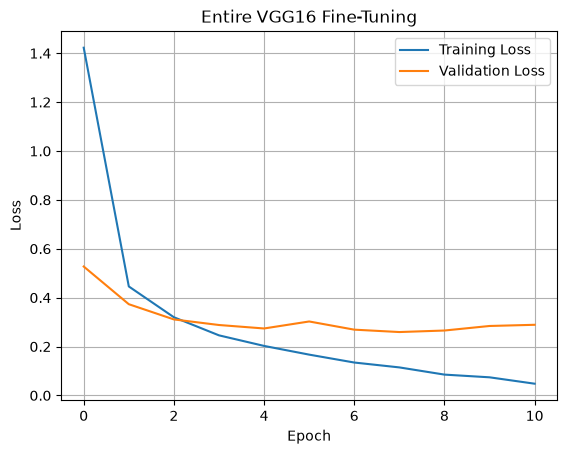

In [12]:
# 9. Plot loss curves for entire fine-tuning
plt.plot(history1.history["loss"], label="Training Loss")
plt.plot(history1.history["val_loss"], label="Validation Loss")
plt.title("Entire VGG16 Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

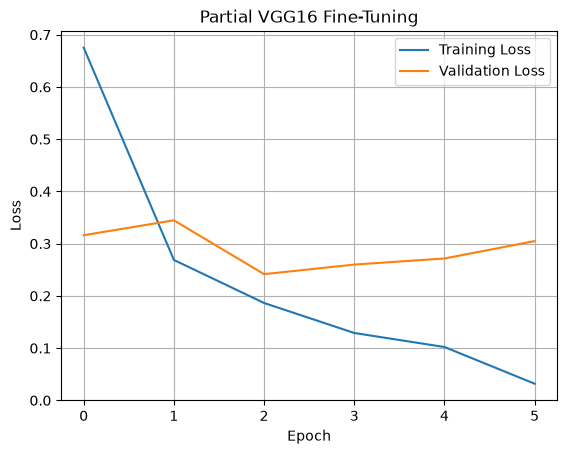

In [13]:
# 10. Plot loss curves for partial fine-tuning
plt.plot(history2.history["loss"], label="Training Loss")
plt.plot(history2.history["val_loss"], label="Validation Loss")
plt.title("Partial VGG16 Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [14]:
# 11. Compare test accuracy
loss1, acc1 = model1.evaluate(x_test, y_test, verbose=1)
loss2, acc2 = model2.evaluate(x_test, y_test, verbose=1)

print("Entire VGG16 Test Accuracy:", acc1)
print("Partial VGG16 Test Accuracy:", acc2)

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9217 - loss: 0.2510
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9200 - loss: 0.2329
Entire VGG16 Test Accuracy: 0.92166668176651
Partial VGG16 Test Accuracy: 0.9200000166893005
